# Netflix Content Rating & Genre Analysis

## Objective
This analysis explores Netflix content ratings and genres to understand the distribution of content across different audience classifications and categories.

The analysis focuses on rating distribution, popular genres, comparisons between Movies and TV Shows, and business insights.

## Dataset
The cleaned Netflix dataset is used as the input for this analysis.

In [14]:
import pandas as pd
import matplotlib.pyplot as plt

In [15]:
df = pd.read_csv("Netflix_Cleaned_Dataset.csv")

print("Dataset Shape:", df.shape)

df.head()

Dataset Shape: (8790, 10)


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [16]:
print("Missing Rating Values:", df['rating'].isnull().sum())

print("\nUnique Ratings:")
print(df['rating'].value_counts(dropna=False))

print("\nMissing Genre Values:", df['listed_in'].isnull().sum())

print("\nSample Genres:")
print(df['listed_in'].head(10))

Missing Rating Values: 0

Unique Ratings:
rating
TV-MA       3205
TV-14       2157
TV-PG        861
R            799
PG-13        490
TV-Y7        333
TV-Y         306
PG           287
TV-G         220
NR            79
G             41
TV-Y7-FV       6
NC-17          3
UR             3
Name: count, dtype: int64

Missing Genre Values: 0

Sample Genres:
0                                        Documentaries
1    Crime TV Shows, International TV Shows, TV Act...
2                   TV Dramas, TV Horror, TV Mysteries
3                   Children & Family Movies, Comedies
4     Dramas, Independent Movies, International Movies
5                         British TV Shows, Reality TV
6                                     Comedies, Dramas
7    Children & Family Movies, Comedies, Music & Mu...
8                         Dramas, International Movies
9           Children & Family Movies, Music & Musicals
Name: listed_in, dtype: object


In [17]:
rating_counts = (
    df['rating']
    .value_counts()
    .reset_index()
)

rating_counts.columns = ['Rating', 'Total Titles']

rating_counts['Percentage'] = (
    rating_counts['Total Titles'] / len(df)
) * 100

rating_counts

,Rating,Total Titles,Percentage
0,TV-MA,3205,36.461889
1,TV-14,2157,24.539249
2,TV-PG,861,9.795222
3,R,799,9.089875
4,PG-13,490,5.574516
5,TV-Y7,333,3.788396
6,TV-Y,306,3.481229
7,PG,287,3.265074
8,TV-G,220,2.502844
9,NR,79,0.898749


In [18]:
top_ratings = rating_counts.head(10)

print("Top 10 Content Ratings:\n")
print(top_ratings.to_string(index=False))

Top 10 Content Ratings:

Rating  Total Titles  Percentage
 TV-MA          3205   36.461889
 TV-14          2157   24.539249
 TV-PG           861    9.795222
     R           799    9.089875
 PG-13           490    5.574516
 TV-Y7           333    3.788396
  TV-Y           306    3.481229
    PG           287    3.265074
  TV-G           220    2.502844
    NR            79    0.898749


In [19]:
rating_by_type = (
    df.groupby(['rating', 'type'])['show_id']
    .nunique()
    .reset_index(name='Total Titles')
)

rating_pivot = rating_by_type.pivot(
    index='rating',
    columns='type',
    values='Total Titles'
).fillna(0)

rating_pivot = rating_pivot.sort_values(
    by='Movie',
    ascending=False
)

rating_pivot

type,Movie,TV Show
rating,,
TV-MA,2062.0,1143.0
TV-14,1427.0,730.0
R,797.0,2.0
TV-PG,540.0,321.0
PG-13,490.0,0.0
PG,287.0,0.0
TV-Y7,139.0,194.0
TV-Y,131.0,175.0
TV-G,126.0,94.0


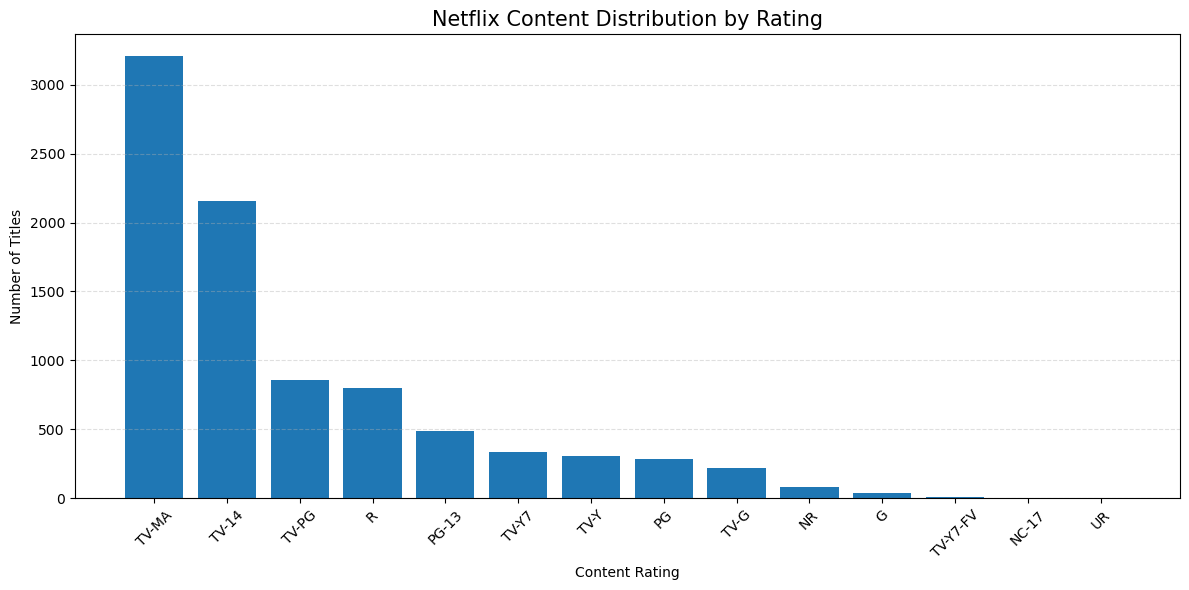

In [20]:
plt.figure(figsize=(12, 6))

plt.bar(
    rating_counts['Rating'],
    rating_counts['Total Titles']
)

plt.title('Netflix Content Distribution by Rating', fontsize=15)
plt.xlabel('Content Rating')
plt.ylabel('Number of Titles')

plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

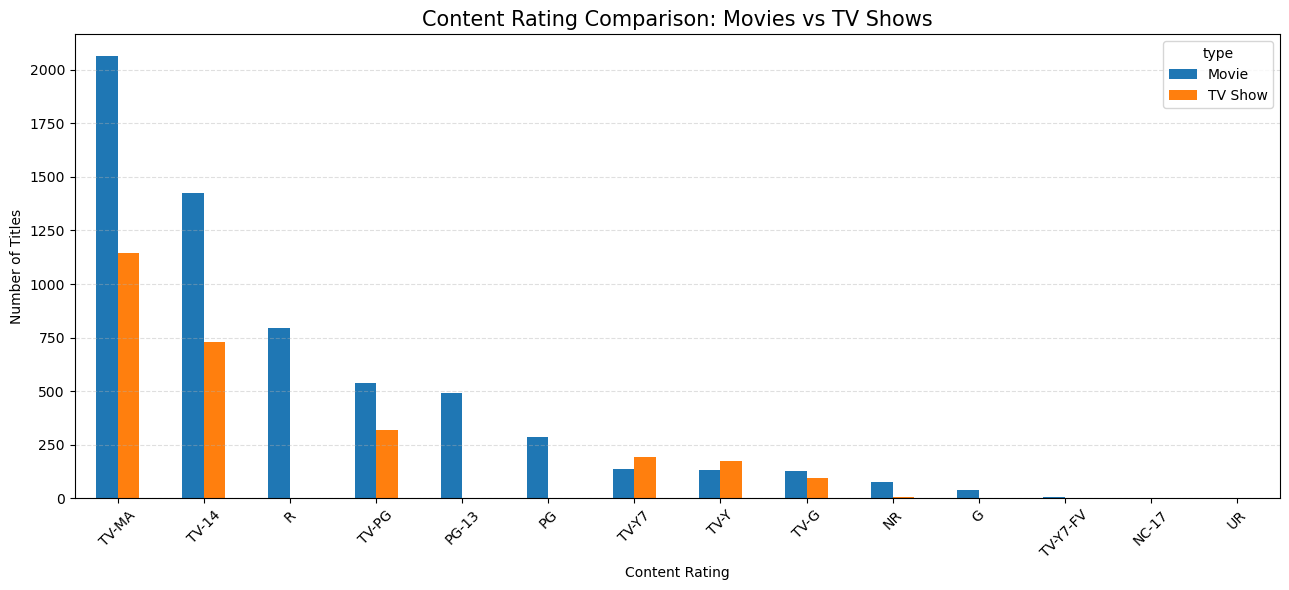

In [21]:
rating_pivot.plot(
    kind='bar',
    figsize=(13, 6)
)

plt.title('Content Rating Comparison: Movies vs TV Shows', fontsize=15)
plt.xlabel('Content Rating')
plt.ylabel('Number of Titles')

plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

In [22]:

# Create a separate row for each genre
genre_df = df[['show_id', 'title', 'type', 'listed_in']].copy()

genre_df['listed_in'] = genre_df['listed_in'].str.split(',')

genre_df = genre_df.explode('listed_in')

genre_df['listed_in'] = genre_df['listed_in'].str.strip()

genre_df = genre_df.rename(columns={'listed_in': 'Genre'})

# Display the extracted genre data
genre_df.head(10)


,show_id,title,type,Genre
0,s1,Dick Johnson Is Dead,Movie,Documentaries
1,s3,Ganglands,TV Show,Crime TV Shows
1,s3,Ganglands,TV Show,International TV Shows
1,s3,Ganglands,TV Show,TV Action & Adventure
2,s6,Midnight Mass,TV Show,TV Dramas
2,s6,Midnight Mass,TV Show,TV Horror
2,s6,Midnight Mass,TV Show,TV Mysteries
3,s14,Confessions of an Invisible Girl,Movie,Children & Family Movies
3,s14,Confessions of an Invisible Girl,Movie,Comedies
4,s8,Sankofa,Movie,Dramas


In [23]:

# Count unique titles in each genre
genre_counts = (
    genre_df.groupby('Genre')['show_id']
    .nunique()
    .reset_index(name='Total Titles')
)

# Sort genres by title count
genre_counts = genre_counts.sort_values(
    by='Total Titles', ascending=False
).reset_index(drop=True)

# Calculate percentage of all genre-title associations
total_associations = genre_counts['Total Titles'].sum()

genre_counts['Percentage'] = (
    genre_counts['Total Titles'] / total_associations
) * 100

genre_counts


,Genre,Total Titles,Percentage
0,International Movies,2752,14.263502
1,Dramas,2426,12.573857
2,Comedies,1674,8.676272
3,International TV Shows,1349,6.991811
4,Documentaries,869,4.503991
5,Action & Adventure,859,4.452161
6,TV Dramas,762,3.949414
7,Independent Movies,756,3.918317
8,Children & Family Movies,641,3.322276
9,Romantic Movies,616,3.192702


In [24]:

# Count unique titles by genre and content type
genre_type = (
    genre_df.groupby(['Genre', 'type'])['show_id']
    .nunique()
    .reset_index(name='Total Titles')
)

# Create comparison table
genre_type_pivot = genre_type.pivot(
    index='Genre',
    columns='type',
    values='Total Titles'
).fillna(0)

# Sort by total genre titles
genre_type_pivot['Total'] = (
    genre_type_pivot['Movie'] + genre_type_pivot['TV Show']
)

genre_type_pivot = genre_type_pivot.sort_values(
    by='Total', ascending=False
)

genre_type_pivot


type,Movie,TV Show,Total
Genre,,,
International Movies,2752.0,0.0,2752.0
Dramas,2426.0,0.0,2426.0
Comedies,1674.0,0.0,1674.0
International TV Shows,0.0,1349.0,1349.0
Documentaries,869.0,0.0,869.0
Action & Adventure,859.0,0.0,859.0
TV Dramas,0.0,762.0,762.0
Independent Movies,756.0,0.0,756.0
Children & Family Movies,641.0,0.0,641.0


In [25]:

# Convert title counts to integers
genre_type_pivot[['Movie', 'TV Show', 'Total']] = (
    genre_type_pivot[['Movie', 'TV Show', 'Total']].astype(int)
)

genre_type_pivot


type,Movie,TV Show,Total
Genre,,,
International Movies,2752,0,2752
Dramas,2426,0,2426
Comedies,1674,0,1674
International TV Shows,0,1349,1349
Documentaries,869,0,869
Action & Adventure,859,0,859
TV Dramas,0,762,762
Independent Movies,756,0,756
Children & Family Movies,641,0,641


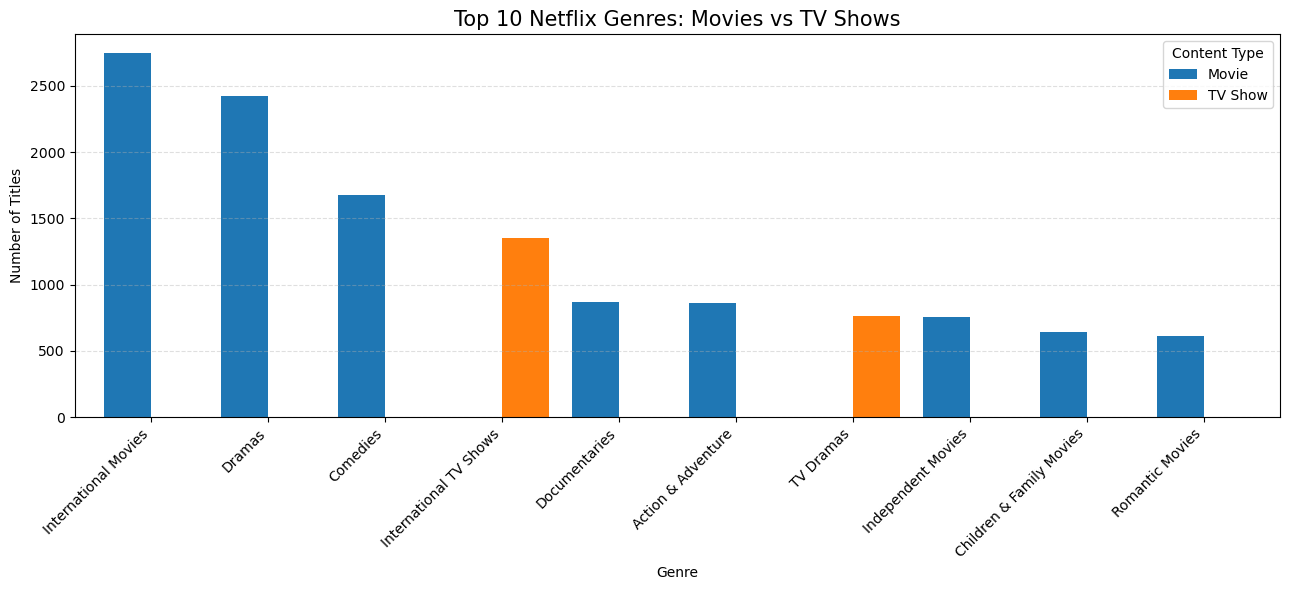

In [26]:

# Select top 10 genres
top_10_genres = genre_type_pivot.head(10)

# Plot comparison
top_10_genres[['Movie', 'TV Show']].plot(
    kind='bar',
    figsize=(13, 6),
    width=0.8
)

plt.title('Top 10 Netflix Genres: Movies vs TV Shows', fontsize=15)
plt.xlabel('Genre')
plt.ylabel('Number of Titles')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Content Type')
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()


### Key Business Insights

1. **Genre Distribution:** International Movies, Dramas, and Comedies are the most represented genres in the Netflix dataset.

2. **Movie Content:** Movies have a strong presence in categories such as International Movies, Dramas, Comedies, Documentaries, and Action & Adventure.

3. **TV Show Content:** International TV Shows, TV Dramas, and TV Comedies are the leading categories among TV Shows.

4. **Content Variety:** Netflix's catalog covers a wide range of genres, including documentaries, children's content, horror, romance, reality TV, and science fiction.

5. **International Content Representation:** International Movies and International TV Shows have a substantial presence in the catalog, highlighting the variety of international content available on Netflix.

### Conclusion

The Content Rating and Genre Analysis provided an overview of Netflix's content classification and genre distribution. The analysis identified TV-MA and TV-14 as the most common content ratings and International Movies, Dramas, and Comedies as the leading genres. Comparing Movies and TV Shows also highlighted differences in their genre distributions.

This analysis helped identify patterns in Netflix's content catalog and demonstrated how Python and Pandas can be used to explore, summarize, and visualize categorical data.